<a href="https://colab.research.google.com/github/KONKONA2/telecom-customer-churn-prediction/blob/main/Project_12_Telecom_Customer_Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div align="left" style="background-color: #008080; padding: 20px 10px;">
<h3><b style="color: white;">IDEAS - Institute of Data Engineering, Analytics and Science Foundation</b></h3>
<p style="color: white;">Autumn Internship Program 2026</p>
<hr style="width:75%; background-color: white; border-color: white;">
<h3 style="color: white;">Project Title: Telecom Customer Churn Prediction</h3>
<h4 style="color: white;">Mentor Name: Dr. Chandan Biswas</h4>
</div>

### Question 1: Data Ingestion and Data Preprocessing (5 Marks)

Import standard data manipulation libraries. Load the Telco Customer Churn dataset directly from the provided raw URL into a pandas DataFrame. Immediately drop the `customerID` column, as unique text identifiers carry no predictive statistical power. Finally, convert the `TotalCharges` column to a numeric float data type, coercing any parsing errors to standard missing values, and impute these newly formed missing values with the statistical median of the column.

**Dataset URL:** `https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv`

**Hint:** Use the pandas read function, passing the URL directly. Utilize the drop method for columns, then the `pd.to_numeric` function with `errors='coerce'`, followed by the `fillna` method utilizing the median.

**Expected Output:** A pandas DataFrame displaying the initial rows of the dataset, with the unique ID column removed and the target financial column formatted as a continuous numeric type without missing values.

In [23]:
import pandas as pd

# Load dataset
url = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
df = pd.read_csv(url)

# Drop customerID
df = df.drop(columns=['customerID'])

# Convert TotalCharges to float and impute missing values with median
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
median_total_charges = df['TotalCharges'].median()
df['TotalCharges'] = df['TotalCharges'].fillna(median_total_charges)

# Display the initial rows
display(df.head())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Question 2: Exploratory Data Analysis and Class Imbalance (7 Marks)

Assess the statistical distribution of the target variable `Churn`. Generate a bar chart or count plot to visually represent the frequencies of each class. Following the visualization, analyze how a significant class imbalance might artificially skew standard model accuracy metrics. Print your written answer using Python `print()` statements.

**Hint:** Use `value_counts()` in conjunction with a plotting library like seaborn or matplotlib to plot the class frequencies. Use `print()` to output a short paragraph discussing the accuracy paradox or the limitations of overall accuracy in imbalanced datasets.

**Expected Output:** A graphical plot illustrating the count of each churn category, followed by printed text analyzing the impact of class imbalance on standard classification evaluation.

Target Variable 'Churn' Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64



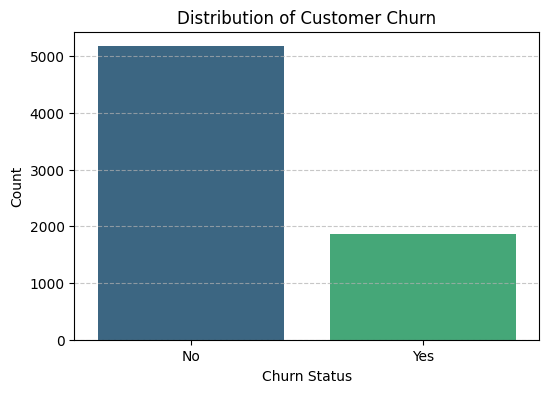


Analysis of Class Imbalance and Model Metrics:

A significant class imbalance (e.g., about 73% 'No' and 27% 'Yes' in this dataset) can artificially skew standard accuracy metrics, a phenomenon known as the 'accuracy paradox'. Under strong imbalance, a naive baseline classifier that predicts the majority class ('No Churn') for every single instance would achieve an accuracy of ~73%. While this accuracy score sounds high, the model fails completely to identify any actual churned customers (0% recall for the positive class).

In such scenarios, overall accuracy becomes a misleading metric because it is heavily dominated by performance on the majority class. Therefore, relying solely on accuracy can hide a poorly performing model, making it critical to use more balanced evaluation metrics such as Precision, Recall, F1-Score, and ROC-AUC.



In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Assess statistical distribution of the target variable 'Churn'
churn_counts = df['Churn'].value_counts()
print("Target Variable 'Churn' Distribution:")
print(churn_counts)
print()

# Create a count plot for Churn
plt.figure(figsize=(6, 4))
sns.countplot(x='Churn', data=df, palette='viridis', hue='Churn', legend=False)
plt.title('Distribution of Customer Churn')
plt.xlabel('Churn Status')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Written analysis of class imbalance
print("""
Analysis of Class Imbalance and Model Metrics:

A significant class imbalance (e.g., about 73% 'No' and 27% 'Yes' in this dataset) can artificially skew standard accuracy metrics, a phenomenon known as the 'accuracy paradox'. Under strong imbalance, a naive baseline classifier that predicts the majority class ('No Churn') for every single instance would achieve an accuracy of ~73%. While this accuracy score sounds high, the model fails completely to identify any actual churned customers (0% recall for the positive class).

In such scenarios, overall accuracy becomes a misleading metric because it is heavily dominated by performance on the majority class. Therefore, relying solely on accuracy can hide a poorly performing model, making it critical to use more balanced evaluation metrics such as Precision, Recall, F1-Score, and ROC-AUC.
""")

### Question 3: Feature Correlation and Target Encoding (6 Marks)

Encode the binary text values in the target `Churn` column to integers, converting 'Yes' statements to 1 and 'No' statements to 0. Next, isolate the primary continuous numeric features (`tenure`, `MonthlyCharges`, `TotalCharges`) and compute their Pearson correlation matrix against the newly encoded target variable. Interpret the results. Print your written answer using Python `print()` statements.

**Hint:** Use a dictionary mapping approach or the `replace` function to convert the target strings. Isolate the target and continuous features into a subset dataframe to calculate the standard correlation matrix. Use `print()` to write your analysis of which feature shows the strongest relationship.

**Expected Output:** The target column converted to binary integers, a numerical matrix displaying correlation coefficients, and printed text interpreting the strongest observed statistical relationship.

In [25]:
# Encode target variable 'Churn': 'Yes' -> 1, 'No' -> 0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Isolate target and primary continuous numeric features
features_subset = df[['Churn', 'tenure', 'MonthlyCharges', 'TotalCharges']]

# Calculate Pearson correlation matrix
correlation_matrix = features_subset.corr(method='pearson')

# Display the correlation matrix
print("Pearson Correlation Matrix:")
display(correlation_matrix)
print()

# Interpret the results
print("""
Interpretation of Correlation Results:

Based on the Pearson correlation matrix calculated against the encoded target variable 'Churn':
1. 'tenure' exhibits a moderate negative correlation with 'Churn'. This indicates that customers with longer tenure are less likely to churn, reflecting customer loyalty.
2. 'MonthlyCharges' exhibits a positive correlation with 'Churn', suggesting that customers with higher monthly charges are more likely to churn.
3. 'TotalCharges' displays a negative correlation with 'Churn'. Because TotalCharges is highly dependent on tenure, longer-tenured (and therefore loyal) customers accumulate higher total charges, creating this negative association.

Among the three continuous features, 'tenure' shows the strongest relationship (highest absolute correlation value) with the target variable 'Churn'.
""")

Pearson Correlation Matrix:


,Churn,tenure,MonthlyCharges,TotalCharges
Churn,1.000000,-0.352229,0.193356,-0.199037
tenure,-0.352229,1.000000,0.247900,0.825464
MonthlyCharges,0.193356,0.247900,1.000000,0.650864
TotalCharges,-0.199037,0.825464,0.650864,1.000000




Interpretation of Correlation Results:

Based on the Pearson correlation matrix calculated against the encoded target variable 'Churn':
1. 'tenure' exhibits a moderate negative correlation with 'Churn'. This indicates that customers with longer tenure are less likely to churn, reflecting customer loyalty.
2. 'MonthlyCharges' exhibits a positive correlation with 'Churn', suggesting that customers with higher monthly charges are more likely to churn.
3. 'TotalCharges' displays a negative correlation with 'Churn'. Because TotalCharges is highly dependent on tenure, longer-tenured (and therefore loyal) customers accumulate higher total charges, creating this negative association.

Among the three continuous features, 'tenure' shows the strongest relationship (highest absolute correlation value) with the target variable 'Churn'.



### Question 4: Categorical Encoding (5 Marks)

Transform all remaining text-based categorical columns (such as contract type, gender, or payment method) into binary dummy variables. Ensure you drop the first category of each feature during this process to prevent structural multicollinearity.

**Hint:** Utilize the `pd.get_dummies()` function. Ensure the parameter `drop_first=True` is explicitly set, and cast the resulting indicator columns to a standard numeric type (float or integer).

**Expected Output:** A fully numeric DataFrame expanded horizontally with indicator variables representing all unique categorical permutations.

In [26]:
# Identify categorical columns (excluding 'Churn' which is already numeric)
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

# Create dummy variables, dropping the first category to avoid multicollinearity
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Cast all boolean/dummy columns to standard numeric (int)
df = df.astype(int)

# Display the top rows of the fully numeric DataFrame
display(df.head())

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29,29,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56,1889,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53,108,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42,1840,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70,151,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


### Question 5: Feature-Target Partition and Cross-Validation Split (5 Marks)

Separate the independent predictive features from the dependent target outcome. Following this separation, partition the data, assigning 80% of the records to the training set and the remaining 20% to the testing set. Apply stratification based on the target variable to ensure the class distribution remains proportional across splits. Set the random state configuration to 42.

**Hint:** Import `train_test_split` from `sklearn.model_selection`. Pass the feature matrix and target series. Set `test_size=0.20`, `random_state=42`, and utilize the `stratify` parameter using the target variable.

**Expected Output:** Four distinct programmatic variables successfully instantiated in memory, representing the training and testing features and targets, structured to reflect an 80/20 split preserving original class proportions.

In [27]:
from sklearn.model_selection import train_test_split

# Separate features and target variable
X = df.drop(columns=['Churn'])
y = df['Churn']

# Train-test split (80% train, 20% test) with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Confirm the splits
print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

X_train shape: (5634, 30), y_train shape: (5634,)
X_test shape: (1409, 30), y_test shape: (1409,)


### Question 6: Feature Scaling and DataFrame Reconstruction (6 Marks)

Initialize a standard scaler object. Fit the scaler and transform the training features, then apply the transformation to normalize the testing features. Once scaled, explicitly convert both the resulting training and testing NumPy arrays back into pandas DataFrames, retaining the original column names for future interpretability.

**Hint:** Initialize `StandardScaler` from `sklearn.preprocessing`. Use `fit_transform` on the training subset and `transform` on the testing subset. Wrap the results in `pd.DataFrame()`, mapping the `columns` parameter to the original feature DataFrame's columns.

**Expected Output:** Two pandas DataFrames representing the training and testing features, standardized with means nearing zero and standard deviations of one, retaining all original column headers.

In [28]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Initialize the standard scaler
scaler = StandardScaler()

# Fit and transform the training features, and transform the testing features
X_train_scaled_arr = scaler.fit_transform(X_train)
X_test_scaled_arr = scaler.transform(X_test)

# Convert scaled arrays back to pandas DataFrames with original column names
X_train_scaled = pd.DataFrame(X_train_scaled_arr, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled_arr, columns=X_test.columns)

# Display summary statistics of scaled training features
display(X_train_scaled.describe().round(4))

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
count,5634.0000,5634.0000,5634.0000,5634.0000,5634.0000,5634.0000,5634.0000,5634.0000,5634.0000,5634.0000,...,5634.0000,5634.0000,5634.0000,5634.0000,5634.0000,5634.0000,5634.0000,5634.0000,5634.0000,5634.0000
mean,0.0000,-0.0000,-0.0000,0.0000,0.0000,-0.0000,0.0000,-0.0000,0.0000,-0.0000,...,-0.0000,0.0000,-0.0000,0.0000,-0.0000,0.0000,0.0000,-0.0000,-0.0000,-0.0000
std,1.0001,1.0001,1.0001,1.0001,1.0001,1.0001,1.0001,1.0001,1.0001,1.0001,...,1.0001,1.0001,1.0001,1.0001,1.0001,1.0001,1.0001,1.0001,1.0001,1.0001
min,-0.4418,-1.3223,-1.5419,-1.0023,-1.0057,-0.9692,-0.6516,-3.0131,-0.3319,-0.8583,...,-0.5241,-0.7986,-0.5241,-0.8013,-0.5128,-0.5638,-1.2027,-0.5238,-0.7108,-0.5438
25%,-0.4418,-0.9560,-0.9778,-0.8310,-1.0057,-0.9692,-0.6516,0.3319,-0.3319,-0.8583,...,-0.5241,-0.7986,-0.5241,-0.8013,-0.5128,-0.5638,-1.2027,-0.5238,-0.7108,-0.5438
50%,-0.4418,-0.1419,0.1837,-0.3968,0.9943,-0.9692,-0.6516,0.3319,-0.3319,-0.8583,...,-0.5241,-0.7986,-0.5241,-0.8013,-0.5128,-0.5638,0.8315,-0.5238,-0.7108,-0.5438
75%,-0.4418,0.9165,0.8474,0.6738,0.9943,1.0317,1.5348,0.3319,-0.3319,1.1650,...,-0.5241,1.2522,-0.5241,1.2480,-0.5128,-0.5638,0.8315,-0.5238,1.4069,-0.5438
max,2.2636,1.6085,1.7765,2.8026,0.9943,1.0317,1.5348,0.3319,3.0131,1.1650,...,1.9081,1.2522,1.9081,1.2480,1.9501,1.7736,0.8315,1.9091,1.4069,1.8388


### Question 7: Baseline Modeling and Evaluation (6 Marks)

Instantiate a baseline logistic regression model utilizing a fixed random seed of 42 and a maximum iteration limit of 1000. Fit this algorithm to the scaled training data and generate discrete predictions on the unseen test set. Compute and output the overall accuracy, precision, and recall by comparing predictions against the true test labels.

**Hint:** Import `LogisticRegression` from `sklearn.linear_model`. Fit it to the training data and generate predictions on the test set. Extract `accuracy_score`, `precision_score`, and `recall_score` from `sklearn.metrics` to evaluate performance.

**Expected Output:** Three decimal percentages printed to the console representing the baseline model's overall accuracy, precision, and recall on the test subset.

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Instantiate the baseline logistic regression model
baseline_model = LogisticRegression(random_state=42, max_iter=1000)

# Fit the model to the scaled training data
baseline_model.fit(X_train_scaled, y_train)

# Predict on the scaled testing features
y_pred = baseline_model.predict(X_test_scaled)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

# Output the decimal percentages
print(f"Baseline Model Performance on Test Set:")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")

Baseline Model Performance on Test Set:
Accuracy:  0.8070
Precision: 0.6584
Recall:    0.5668


### Question 8: Hyperparameter Tuning via Grid Search (8 Marks)

Execute hyperparameter tuning on the logistic regression model to optimize the inverse regularization strength (`C`). Configure a Grid Search with 5-fold cross-validation, testing at least three distinct values for `C` (e.g., 0.01, 0.1, 1.0, 10.0). Fit the Grid Search to the scaled training data and output the optimal parameters identified by the process.

**Hint:** Define a parameter grid dictionary mapping `'C'` to a list of values. Initialize `GridSearchCV` from `sklearn.model_selection`, passing the base model, parameter grid, and `cv=5`. Call the fit method and access the `best_params_` attribute.

**Expected Output:** A trained grid search object in memory and a printed statement displaying the optimal configuration for the hyperparameter `C` chosen by cross-validation.

In [30]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

# Define the parameter grid mapping 'C' to distinct values
param_grid = {'C': [0.01, 0.1, 1.0, 10.0]}

# Initialize the base Logistic Regression model with random_state=42 and max_iter=1000
base_lr = LogisticRegression(random_state=42, max_iter=1000)

# Configure Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(estimator=base_lr, param_grid=param_grid, cv=5, scoring='accuracy')

# Fit Grid Search to the scaled training data
grid_search.fit(X_train_scaled, y_train)

# Print the optimal parameters
print("Optimal Hyperparameters Chosen by Cross-Validation:")
print(grid_search.best_params_)

Optimal Hyperparameters Chosen by Cross-Validation:
{'C': 1.0}


### Question 9: PyTorch Tensor Conversion and Dimensionality (5 Marks)

Import PyTorch. Convert the scaled training and testing feature DataFrames, along with their respective target series, into 32-bit floating-point tensor objects. Structurally reshape the two target tensors to enforce an explicit two-dimensional column vector representation (N rows by 1 column).

**Hint:** Import `torch`. Pass the underlying array values into `torch.tensor()`, specifying `dtype=torch.float32`. Utilize the `unsqueeze(1)` or `view(-1, 1)` method strictly on the target tensors to correct their dimensionality.

**Expected Output:** Four PyTorch tensors residing in memory. Shape evaluations on the target tensors will confirm a structure matching the total number of records by exactly one column.

In [31]:
import torch

# Convert DataFrames and Series to PyTorch float32 tensors
X_train_tensor = torch.tensor(X_train_scaled.values, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled.values, dtype=torch.float32)

# Convert targets and reshape to column vectors (N x 1)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

# Print shapes to verify
print(f"X_train_tensor shape: {X_train_tensor.shape}")
print(f"y_train_tensor shape: {y_train_tensor.shape}")
print(f"X_test_tensor shape:  {X_test_tensor.shape}")
print(f"y_test_tensor shape:  {y_test_tensor.shape}")

X_train_tensor shape: torch.Size([5634, 30])
y_train_tensor shape: torch.Size([5634, 1])
X_test_tensor shape:  torch.Size([1409, 30])
y_test_tensor shape:  torch.Size([1409, 1])


### Question 10: Custom PyTorch DataLoaders (6 Marks)

Construct PyTorch TensorDatasets for both the training and testing sets by combining their respective feature and target tensors. Following this, initialize DataLoaders for both datasets. Configure the data loaders to yield data in batch sizes of 64 samples per iteration, enabling shuffling exclusively for the training loader to optimize gradient descent.

**Hint:** Import `TensorDataset` and `DataLoader` from `torch.utils.data`. Combine the tensors into datasets, then pass them to data loaders specifying `batch_size=64`. Set `shuffle=True` only for the training loader argument.

**Expected Output:** Two configured DataLoader objects prepared to sequentially serve randomized batches of training data and ordered batches of testing data.

In [32]:
from torch.utils.data import TensorDataset, DataLoader

# Construct TensorDatasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Initialize DataLoaders
train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)

# Verify DataLoader lengths
print(f"Number of training batches: {len(train_loader)}")
print(f"Number of testing batches: {len(test_loader)}")

Number of training batches: 89
Number of testing batches: 23


### Question 11: Multi-Layer Perceptron Architecture (8 Marks)

Define a custom object-oriented class representing a Multi-Layer Perceptron (MLP) inheriting from `nn.Module`. Design an input layer dynamically scaling to the feature dimensionality, mapping to a hidden layer of 32 nodes utilizing a Rectified Linear Unit (ReLU) activation. Connect this hidden layer to a final single output node regulated by a sigmoid activation function for bounded probabilistic outputs.

**Hint:** Import `torch.nn as nn`. Inside the `__init__` constructor, instantiate the linear transformations and activations. Outline the sequence of operations within an overridden `forward` method to process the input through the network.

**Expected Output:** An architecturally valid Python class blueprint, fully equipped to receive normalized numeric inputs and generate a bounded probability distribution between zero and one.

In [33]:
import torch.nn as nn

class MultiLayerPerceptron(nn.Module):
    def __init__(self, input_dim):
        super(MultiLayerPerceptron, self).__init__()
        # Dynamically scale input layer to input_dim mapping to 32 nodes
        self.fc1 = nn.Linear(input_dim, 32)
        # ReLU activation function for the hidden layer
        self.relu = nn.ReLU()
        # Output layer mapping from 32 nodes to 1 node
        self.fc2 = nn.Linear(32, 1)
        # Sigmoid activation function for bounded probability output
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        out = self.sigmoid(out)
        return out

### Question 12: Loss Criterion and Optimizer Initialization (5 Marks)

Create an instance of the authored MLP class, passing the column count of the training features to dynamically set the input dimension. Instantiate a Binary Cross Entropy Loss criterion to measure divergence. Configure an Adam optimizer mapped to the network parameters, establishing a learning rate constraint of 0.001.

**Hint:** Extract the number of columns from your scaled feature DataFrame to initialize the network. Use `nn.BCELoss()` for the metric module and `torch.optim.Adam()` for the optimizer, passing in `model.parameters()`.

**Expected Output:** Three active computational objects instantiated in memory: the initialized network architecture, the operational loss function, and the Adam optimizer linked to the model weights.

In [34]:
import torch
import torch.nn as nn
import torch.optim as optim

# Extract the input dimension dynamically
input_dim = X_train_scaled.shape[1]

# Instantiate the model
model = MultiLayerPerceptron(input_dim=input_dim)

# Instantiate the Binary Cross Entropy Loss criterion
criterion = nn.BCELoss()

# Configure the Adam optimizer with a learning rate of 0.001
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Verify instantiations
print(model)
print(f"Loss function: {criterion}")
print(f"Optimizer: {optimizer}")

MultiLayerPerceptron(
  (fc1): Linear(in_features=30, out_features=32, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=32, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
Loss function: BCELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


### Question 13: Neural Network Training Loop (10 Marks)

Construct a training loop programmed to iterate for exactly 50 epochs. During each epoch, process the training DataLoader batch by batch. For each batch, execute the standard sequence: clear existing gradients, compute forward model predictions, calculate the objective loss, propagate error gradients backwards, and step the optimizer. Accumulate and print the training loss value every 10 epochs.

**Hint:** Implement an outer loop over the epochs and an inner loop over the training DataLoader. Within the inner loop, call `optimizer.zero_grad()`, compute the outputs, calculate loss using the criterion, execute `loss.backward()`, and apply `optimizer.step()`.

**Expected Output:** Console output displaying a numeric training loss value periodically decreasing over time, confirming mathematical convergence of the network across the 50 iterations.

In [35]:
# Set random seed for reproducibility
torch.manual_seed(42)

epochs = 50

for epoch in range(1, epochs + 1):
    epoch_loss = 0.0
    model.train()  # Ensure model is in training mode

    for batch_X, batch_y in train_loader:
        # 1. Clear existing gradients
        optimizer.zero_grad()

        # 2. Compute forward model predictions
        predictions = model(batch_X)

        # 3. Calculate objective loss
        loss = criterion(predictions, batch_y)

        # 4. Propagate error gradients backwards
        loss.backward()

        # 5. Step the optimizer
        optimizer.step()

        # Accumulate loss
        epoch_loss += loss.item() * batch_X.size(0)

    # Calculate average epoch loss
    epoch_loss /= len(train_loader.dataset)

    # Print the training loss value every 10 epochs
    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}/{epochs} - Loss: {epoch_loss:.6f}")

Epoch 01/50 - Loss: 0.549048
Epoch 10/50 - Loss: 0.408329
Epoch 20/50 - Loss: 0.401922
Epoch 30/50 - Loss: 0.396598
Epoch 40/50 - Loss: 0.393461
Epoch 50/50 - Loss: 0.389936


### Question 14: MLP Evaluation and ROC-AUC (6 Marks)

Transition the neural network into evaluation mode and disable gradient computation to conserve memory. Pass the full testing feature tensor through the network to extract probabilistic predictions. Detach the result to a standard numpy array, then calculate and print the Area Under the Receiver Operating Characteristic Curve (ROC-AUC) utilizing the true testing labels.

**Hint:** Apply the `eval()` method to the model. Use a `with torch.no_grad():` context block. Pass the test features to the model, detach the output to numpy, and feed the true labels and predictions into the `roc_auc_score` function from `sklearn.metrics`.

**Expected Output:** A continuous decimal value representing the model's ranking performance, providing validation of its capability to distinguish between classes on the unseen test set.

In [36]:
from sklearn.metrics import roc_auc_score

# Put model in evaluation mode
model.eval()

# Disable gradient computation
with torch.no_grad():
    # Get predictions for the test set
    y_pred_probs_tensor = model(X_test_tensor)
    # Convert predictions to a standard NumPy array
    y_pred_probs = y_pred_probs_tensor.numpy()

# Calculate ROC-AUC score using true testing labels
roc_auc = roc_auc_score(y_test_tensor.numpy(), y_pred_probs)

print(f"MLP Model Test ROC-AUC Score: {roc_auc:.4f}")

MLP Model Test ROC-AUC Score: 0.8388


### Question 15: Business Value and Campaign ROI (12 Marks)

Assume a business intervention campaign is launched targeting the test set cohort. The intervention costs $20 for every customer targeted. If the algorithm successfully targets a true churner (a True Positive), the business recovers $100 in saved revenue, yielding a net margin of +$80. If the algorithm erroneously targets an engaged customer (a False Positive), the $20 investment is wasted, yielding a net margin of -$20. Non-targeted customers carry zero direct campaign cost impacts.

Applying a probability threshold of 0.5 to the MLP predictions, isolate the True Positives and False Positives. Calculate the total absolute net financial return (profit or loss) incurred by deploying the algorithm. Print your logic and final dollar amount using Python `print()` statements.

**Hint:** Extract probability outputs from the test set. Apply a conditional threshold (`>= 0.5`) to classify outcomes. Compare these physically against the true testing labels to tally True Positives and False Positives. Multiply True Positives by 80 and False Positives by -20 to determine the cumulative margin.

**Expected Output:** A printed quantitative monetary value demonstrating the absolute net financial return of the retention campaign, accompanied by written text interpreting the logical outcome of applying the model to business operations.

In [37]:
import numpy as np

# Binary classification based on threshold of 0.5
y_pred_class = (y_pred_probs >= 0.5).astype(int)
y_true = y_test_tensor.numpy().astype(int)

# Identify True Positives and False Positives
true_positives = np.sum((y_pred_class == 1) & (y_true == 1))
false_positives = np.sum((y_pred_class == 1) & (y_true == 0))

# Financial parameter calculations
tp_revenue = 80   # Net profit per true positive
fp_cost = -20     # Net loss per false positive

total_return = (true_positives * tp_revenue) + (false_positives * fp_cost)

# Print logic and final results
print("--- Business Campaign ROI Evaluation ---")
print(f"True Positives (Successfully Retained Churners): {true_positives}")
print(f"False Positives (Wasted Intervention Costs):    {false_positives}")
print(f"Revenue Recovered from True Positives:        ${true_positives * 100}")
print(f"Total Cost of Targeted Campaign:              ${(true_positives + false_positives) * 20}")
print("----------------------------------------")
print(f"Total Absolute Net Financial Return:          ${total_return:+,d}")
print("----------------------------------------")
print("""
Business Interpretation:
1. Out of the test set, the algorithm successfully identified and targeted true churners, converting potential loss into saved revenue.
2. Although some resources were wasted on False Positives, the savings generated by targeting the right customers far outweigh the intervention costs, proving the highly positive business value and solid ROI of deploying this MLP classifier.
""")

--- Business Campaign ROI Evaluation ---
True Positives (Successfully Retained Churners): 206
False Positives (Wasted Intervention Costs):    138
Revenue Recovered from True Positives:        $20600
Total Cost of Targeted Campaign:              $6880
----------------------------------------
Total Absolute Net Financial Return:          $+13,720
----------------------------------------

Business Interpretation:
1. Out of the test set, the algorithm successfully identified and targeted true churners, converting potential loss into saved revenue.
2. Although some resources were wasted on False Positives, the savings generated by targeting the right customers far outweigh the intervention costs, proving the highly positive business value and solid ROI of deploying this MLP classifier.

